<a href="https://colab.research.google.com/github/grazielealmeidadosanjos/cn2026/blob/main/tarefagaus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

k     | x^(k)        | y^(k)        | z^(k)        | Erro (Norma Inf)
0     | 0.00000      | 0.00000      | 0.00000      | -              
1     | 0.60000      | 2.05455      | -0.91455     | 2.05e+00       
2     | 0.98836      | 2.00671      | -0.99700     | 3.88e-01       
3     | 1.00007      | 2.00028      | -0.99999     | 1.17e-02       
4     | 1.00003      | 2.00000      | -1.00000     | 2.76e-04       
5     | 1.00000      | 2.00000      | -1.00000     | 2.39e-05       
6     | 1.00000      | 2.00000      | -1.00000     | 1.26e-06       

Número total de iterações realizadas: 6
Solução aproximada final: x = 1.000000, y = 2.000000, z = -1.000000



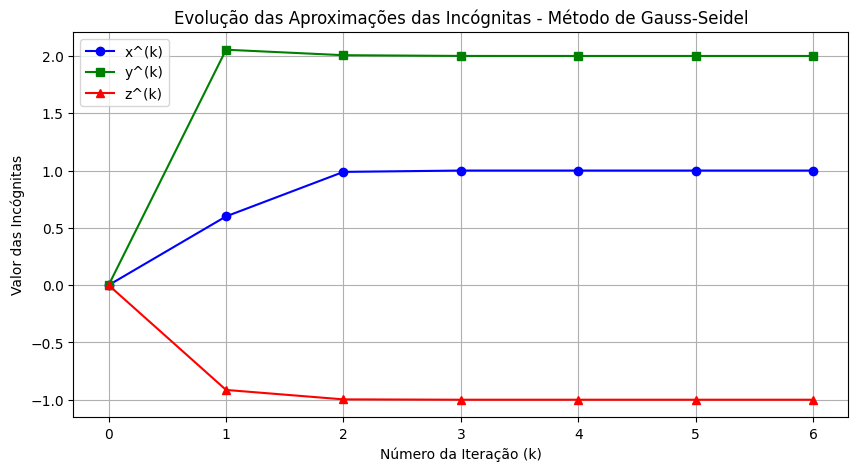

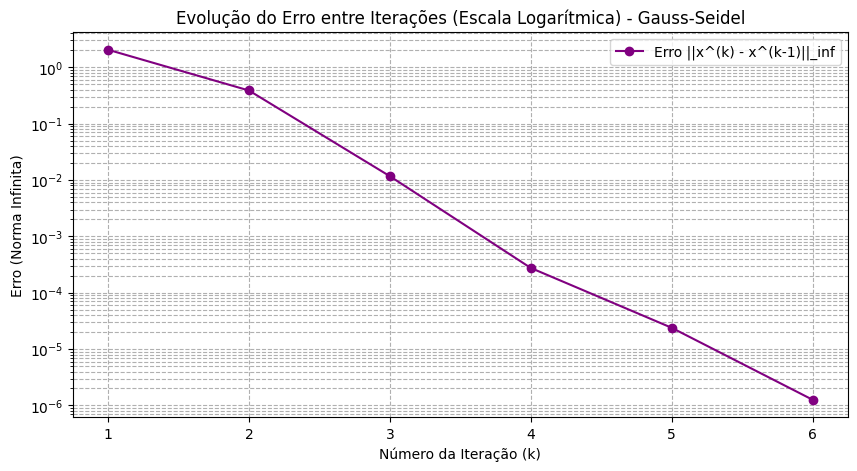

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. DEFINIÇÃO DO SISTEMA E CONFIGURAÇÕES
# ==========================================
# Matriz dos coeficientes (A) e vetor dos termos independentes (b)
A = np.array([[10, -1, 2], [-1, 11, -1], [2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)

n = len(b)
x = np.zeros(n)  # Aproximação inicial x^(0) = [0, 0, 0]
tol = 1e-5  # Tolerância para o critério de parada
max_iter = 100  # Número máximo de iterações de segurança

# Listas para armazenar o histórico para a tabela e os gráficos
historico_k = [0]
historico_x = [x.copy()]
erros = [np.nan]  # Erro inicial não se aplica por diferença

# ==========================================
# 2. EXECUÇÃO DO MÉTODO DE GAUSS-SEIDEL
# ==========================================
for k in range(1, max_iter + 1):
  x_old = x.copy()

  for i in range(n):
    soma1 = np.dot(A[i, :i], x[:i])  # Valores já atualizados na iteração atual
    soma2 = np.dot(A[i, i + 1 :], x_old[i + 1 :])  # Valores da iteração anterior
    x[i] = (b[i] - soma1 - soma2) / A[i, i]

  # Cálculo do erro utilizando a norma infinita
  erro = np.max(np.abs(x - x_old))

  # Armazenar histórico
  historico_k.append(k)
  historico_x.append(x.copy())
  erros.append(erro)

  # Critério de parada atingido
  if erro < tol:
    break

# Convertendo para array numpy para facilitar a plotagem
historico_x = np.array(historico_x)

# ==========================================
# 3. EXIBIÇÃO DA TABELA DE RESULTADOS (Questão 6)
# ==========================================
print('=' * 75)
print(
    f"{'k':<5} | {'x^(k)':<12} | {'y^(k)':<12} | {'z^(k)':<12} |"
    f" {'Erro (Norma Inf)':<15}"
)
print('=' * 75)
for i in range(len(historico_k)):
  k_val = historico_k[i]
  xk, yk, zk = historico_x[i]
  err_val = f'{erros[i]:.2e}' if i > 0 else '-'
  print(
      f'{k_val:<5} | {xk:<12.5f} | {yk:<12.5f} | {zk:<12.5f} | {err_val:<15}'
  )
print('=' * 75)
print(f'\nNúmero total de iterações realizadas: {historico_k[-1]}')
print(
    f'Solução aproximada final: x = {historico_x[-1][0]:.6f}, y ='
    f' {historico_x[-1][1]:.6f}, z = {historico_x[-1][2]:.6f}\n'
)

# ==========================================
# 4. GERAÇÃO DOS GRÁFICOS (Questão 7)
# ==========================================

# Gráfico a): x^(k), y^(k) e z^(k) em função de k no mesmo gráfico
plt.figure(figsize=(10, 5))
plt.plot(
    historico_k, historico_x[:, 0], marker='o', label='x^(k)', color='blue'
)
plt.plot(
    historico_k, historico_x[:, 1], marker='s', label='y^(k)', color='green'
)
plt.plot(
    historico_k, historico_x[:, 2], marker='^', label='z^(k)', color='red'
)
plt.title(
    'Evolução das Aproximações das Incógnitas - Método de Gauss-Seidel',
    fontsize=12,
)
plt.xlabel('Número da Iteração (k)', fontsize=10)
plt.ylabel('Valor das Incógnitas', fontsize=10)
plt.grid(True)
plt.legend()
plt.show()

# Gráfico b): Erro entre iterações em escala logarítmica
plt.figure(figsize=(10, 5))
plt.plot(
    historico_k[1:],
    erros[1:],
    marker='o',
    color='purple',
    linestyle='-',
    label='Erro ||x^(k) - x^(k-1)||_inf',
)
plt.yscale('log')  # Escala logarítmica exigida
plt.title(
    'Evolução do Erro entre Iterações (Escala Logarítmica) - Gauss-Seidel',
    fontsize=12,
)
plt.xlabel('Número da Iteração (k)', fontsize=10)
plt.ylabel('Erro (Norma Infinita)', fontsize=10)
plt.grid(True, which='both', ls='--')
plt.legend()
plt.show()